Ano PRODES 18-19: iniciado
  Total: 2.024.694 | Com DETER: 37.409 | DETER + focos: 2.104 | 5,62% | Tempo: 00:00:59
Ano PRODES 19-20: iniciado
  Total: 2.024.694 | Com DETER: 25.230 | DETER + focos: 1.958 | 7,76% | Tempo: 00:01:00
Ano PRODES 20-21: iniciado
  Total: 2.024.694 | Com DETER: 25.630 | DETER + focos: 2.482 | 9,68% | Tempo: 00:01:00
Ano PRODES 21-22: iniciado
  Total: 2.024.694 | Com DETER: 23.451 | DETER + focos: 2.665 | 11,36% | Tempo: 00:01:00
Ano PRODES 22-23: iniciado
  Total: 2.024.694 | Com DETER: 28.032 | DETER + focos: 3.619 | 12,91% | Tempo: 00:01:03
Ano PRODES 23-24: iniciado
  Total: 2.024.694 | Com DETER: 36.920 | DETER + focos: 4.227 | 11,45% | Tempo: 00:01:03
Ano PRODES 24-25: iniciado
  Total: 2.024.694 | Com DETER: 27.715 | DETER + focos: 3.261 | 11,77% | Tempo: 00:01:01
Ano PRODES 25-26: iniciado
  Total: 2.024.694 | Com DETER: 36.785 | DETER + focos: 3.505 | 9,53% | Tempo: 00:01:02

Ecorregiões: iniciado

RESULTADOS POR ANO PRODES — PERCENTUAL SOBRE GRIDS C

,ANO_PRODES,GRIDS_TOTAIS,GRIDS_COM_DETER,GRIDS_DETER_FOCOS,PERCENTUAL
0,18-19,2024694,37409,2104,5.62
1,19-20,2024694,25230,1958,7.76
2,20-21,2024694,25630,2482,9.68
3,21-22,2024694,23451,2665,11.36
4,22-23,2024694,28032,3619,12.91
5,23-24,2024694,36920,4227,11.45
6,24-25,2024694,27715,3261,11.77
7,25-26,2024694,36785,3505,9.53



RESULTADOS POR ECORREGIÃO — GRIDS ÚNICOS NOS OITO ANOS


,CODIGO,ECORREGIAO,GRIDS_TOTAIS,GRIDS_COM_DETER,GRIDS_DETER_FOCOS,PERCENTUAL
0,1,Alto Parnaíba,173006,34893,5536,15.87
1,2,Alto São Francisco,84936,4379,234,5.34
2,3,Araguaia Tocantins,291206,42649,4595,10.77
3,4,Bananal,77395,7524,821,10.91
4,5,Basaltos do Paraná,112888,1282,35,2.73
5,6,Bico do Papagaio,55117,10774,1165,10.81
6,7,Centro-norte Piauiense,54377,3817,542,14.20
7,8,Chapada dos Parecis,125837,5849,743,12.70
8,9,Chapadão do São Francisco,121231,19224,2440,12.69
9,10,Complexo Bodoquena,36964,2982,174,5.84


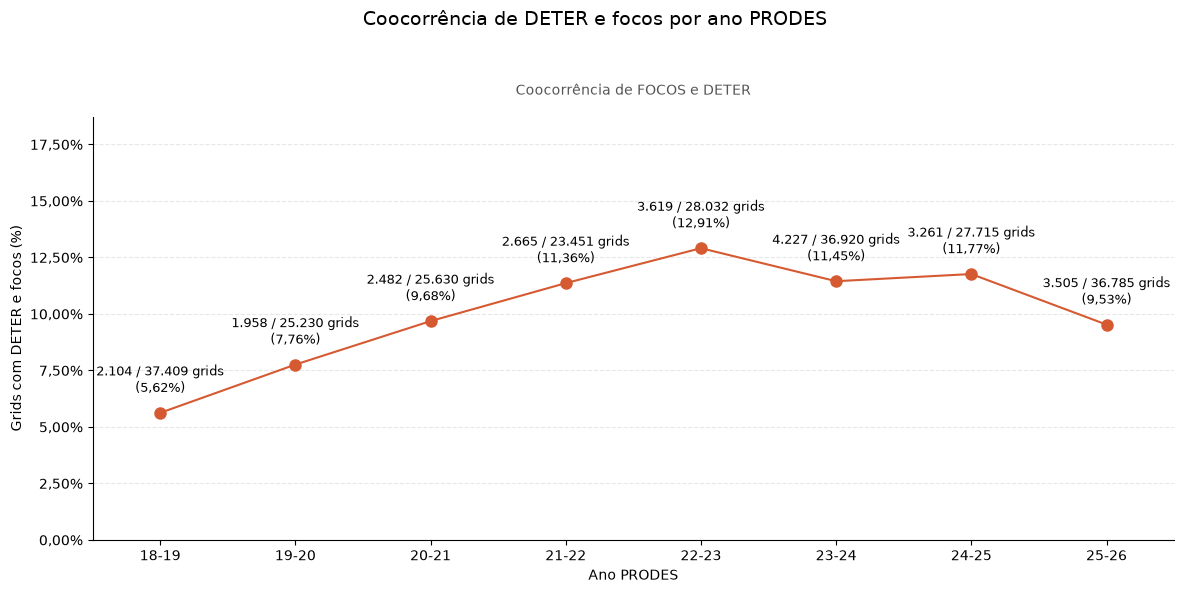


Arquivos salvos em: C:\Users\gabri\OneDrive\Cerrado\SBSR\base_cartografica\analise_18_25_pos_vagner\analise_simples
Tempo total: 00:08:14


In [4]:
# Se necessário, execute antes em outra célula:
# %pip install pandas pyogrio matplotlib

from pathlib import Path
from time import perf_counter
import gc

import pandas as pd
import pyogrio
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display


# ============================================================
# CONFIGURAÇÃO
# ============================================================

BASE = Path(
    r"C:\Users\gabri\OneDrive\Cerrado\SBSR\base_cartografica"
    r"\analise_18_25_pos_vagner"
)

ENTRADA = BASE / "outputs"
SAIDA = BASE / "analise_simples"
ANOS = range(2018, 2026)

NOMES_ECOS = {
    0: "Sem ecorregião",
    1: "Alto Parnaíba",
    2: "Alto São Francisco",
    3: "Araguaia Tocantins",
    4: "Bananal",
    5: "Basaltos do Paraná",
    6: "Bico do Papagaio",
    7: "Centro-norte Piauiense",
    8: "Chapada dos Parecis",
    9: "Chapadão do São Francisco",
    10: "Complexo Bodoquena",
    11: "Costeiro",
    12: "Depressão Cárstica do São Francisco",
    13: "Depressão Cuiabana",
    14: "Jequitinhonha",
    15: "Paracatu",
    16: "Paraná Guimarães",
    17: "Planalto Central",
    18: "Vão do Paranã",
    19: "Floresta de Cocais",
    20: "Parnaguá",
}

# Usa o campo criado pelo script de processamento para cada ano PRODES.
CAMPOS = ["grid_id", "FOCO", "presenca_deter", "ECORREGIOES"]


# ============================================================
# FUNÇÕES
# ============================================================

def tempo_texto(segundos):
    horas, resto = divmod(int(segundos), 3600)
    minutos, segundos = divmod(resto, 60)
    return f"{horas:02d}:{minutos:02d}:{segundos:02d}"


def numero(valor, _=None):
    return f"{valor:,.0f}".replace(",", ".")


def porcentagem(numerador, denominador):
    # Sem grids com DETER, o percentual é indefinido, e não zero.
    return 100 * numerador / denominador if denominador else float("nan")


def percentual_texto(valor):
    if pd.isna(valor):
        return "sem grids com DETER"
    return f"{valor:.2f}%".replace(".", ",")


def normalizar_ecos(valor):
    if pd.isna(valor) or str(valor).strip() in ("", "NENHUMA"):
        return "0"

    partes = str(valor).strip().split("-")

    if any(not p.isdigit() or int(p) <= 0 for p in partes):
        raise ValueError(f"Código de ecorregião inválido: {valor!r}")

    return "-".join(str(c) for c in sorted(set(map(int, partes))))


def ler_ano(arquivo):
    campos_disponiveis = set(pyogrio.read_info(arquivo)["fields"])
    faltantes = set(CAMPOS) - campos_disponiveis

    if faltantes:
        orientacao = (
            " Execute antes o processamento que cria presenca_deter "
            "nos GeoJSONs anuais."
            if "presenca_deter" in faltantes else ""
        )
        raise ValueError(
            f"{arquivo.name}: campos ausentes: {sorted(faltantes)}."
            f"{orientacao}"
        )

    # Lê somente os atributos necessários, sem carregar geometrias.
    df = pyogrio.read_dataframe(
        arquivo,
        columns=CAMPOS,
        read_geometry=False,
    )

    if df.empty or df["grid_id"].isna().any():
        raise ValueError(f"{arquivo.name}: camada vazia ou grid_id nulo.")

    if df["grid_id"].duplicated().any():
        raise ValueError(f"{arquivo.name}: grid_id duplicado.")

    df = df.set_index("grid_id")

    for campo in ["FOCO", "presenca_deter"]:
        df[campo] = df[campo].astype("string").str.strip().str.upper()

        if not df[campo].isin(["SIM", "NAO"]).all():
            raise ValueError(
                f"{arquivo.name}: {campo} contém valores diferentes "
                "de SIM/NAO."
            )

    df["ECORREGIOES"] = (
        df["ECORREGIOES"].map(normalizar_ecos).astype("category")
    )

    # Cada grid entra uma vez, independentemente da quantidade de polígonos.
    df["COM_DETER"] = df["presenca_deter"].eq("SIM")
    df["AMBOS"] = df["FOCO"].eq("SIM") & df["COM_DETER"]

    return df[["ECORREGIOES", "COM_DETER", "AMBOS"]]


# ============================================================
# LEITURA DOS OITO ANOS
# ============================================================

inicio_total = perf_counter()

arquivos = [
    (
        ano,
        ENTRADA / f"ano_prodes_{ano % 100:02d}_{(ano + 1) % 100:02d}.geojson",
    )
    for ano in ANOS
]

faltantes = [str(arquivo) for _, arquivo in arquivos if not arquivo.is_file()]

if faltantes:
    raise FileNotFoundError(
        "Arquivos não encontrados:\n" + "\n".join(faltantes)
    )

SAIDA.mkdir(parents=True, exist_ok=True)

resultados_anuais = []
referencia = None
deter_algum_ano = None
ambos_algum_ano = None

for ano, arquivo in arquivos:
    inicio_ano = perf_counter()
    rotulo = f"{ano % 100:02d}-{(ano + 1) % 100:02d}"

    print(f"Ano PRODES {rotulo}: iniciado", flush=True)

    df = ler_ano(arquivo)

    if referencia is None:
        referencia = df["ECORREGIOES"].copy()
        deter_algum_ano = df["COM_DETER"].copy()
        ambos_algum_ano = df["AMBOS"].copy()

    else:
        if (
            len(df) != len(referencia)
            or not referencia.index.isin(df.index).all()
        ):
            raise ValueError(
                f"Ano {rotulo}: o conjunto de grids mudou."
            )

        # Alinha pelo grid_id, independentemente da ordem das linhas.
        df = df.reindex(referencia.index)

        if not df["ECORREGIOES"].astype("string").equals(
            referencia.astype("string")
        ):
            raise ValueError(
                f"Ano {rotulo}: as ecorregiões dos grids mudaram."
            )

        deter_algum_ano = deter_algum_ano | df["COM_DETER"]
        # AMBOS já exige DETER e focos no mesmo ano PRODES.
        ambos_algum_ano = ambos_algum_ano | df["AMBOS"]

    total = len(df)
    com_deter = int(df["COM_DETER"].sum())
    com_ambos = int(df["AMBOS"].sum())
    percentual = porcentagem(com_ambos, com_deter)

    resultados_anuais.append({
        "ANO_PRODES": rotulo,
        "GRIDS_TOTAIS": total,
        "GRIDS_COM_DETER": com_deter,
        "GRIDS_DETER_FOCOS": com_ambos,
        "PERCENTUAL": percentual,
    })

    print(
        f"  Total: {numero(total)} | "
        f"Com DETER: {numero(com_deter)} | "
        f"DETER + focos: {numero(com_ambos)} | "
        f"{percentual_texto(percentual)} | "
        f"Tempo: {tempo_texto(perf_counter() - inicio_ano)}",
        flush=True,
    )

    del df
    gc.collect()

tabela_anual = pd.DataFrame(resultados_anuais)


# ============================================================
# ECORREGIÕES: CADA GRID CONTADO UMA VEZ NO PERÍODO
# ============================================================

print("\nEcorregiões: iniciado", flush=True)

base_ecos = pd.DataFrame({
    "ECORREGIOES": referencia,
    "COM_DETER": deter_algum_ano,
    "AMBOS": ambos_algum_ano,
})

contagens = {}

# Agrupa por combinações existentes para evitar expandir todos os grids.
# Um grid que cruza duas ecorregiões entra uma vez em cada uma delas.
for combinacao, grupo in base_ecos.groupby(
    "ECORREGIOES", observed=True
):
    total = len(grupo)
    com_deter = int(grupo["COM_DETER"].sum())
    com_ambos = int(grupo["AMBOS"].sum())

    for codigo in map(int, str(combinacao).split("-")):
        if codigo not in contagens:
            contagens[codigo] = [0, 0, 0]

        contagens[codigo][0] += total
        contagens[codigo][1] += com_deter
        contagens[codigo][2] += com_ambos

# Aqui o denominador é a união dos grids com DETER em algum dos oito anos.
# O numerador é a união dos grids com DETER e focos no mesmo ano PRODES.
# Nenhum grid é contado novamente por aparecer em vários anos.
tabela_ecos = pd.DataFrame([
    {
        "CODIGO": codigo,
        "ECORREGIAO": NOMES_ECOS.get(codigo, f"Código {codigo}"),
        "GRIDS_TOTAIS": valores[0],
        "GRIDS_COM_DETER": valores[1],
        "GRIDS_DETER_FOCOS": valores[2],
        "PERCENTUAL": porcentagem(valores[2], valores[1]),
    }
    for codigo, valores in sorted(contagens.items())
])


# ============================================================
# TABELAS
# ============================================================

tabela_anual.to_csv(
    SAIDA / "tabela_por_ano.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

tabela_ecos.to_csv(
    SAIDA / "tabela_por_ecorregiao.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

print("\nRESULTADOS POR ANO PRODES — PERCENTUAL SOBRE GRIDS COM DETER DO ANO")
display(tabela_anual.round({"PERCENTUAL": 2}))

print("\nRESULTADOS POR ECORREGIÃO — GRIDS ÚNICOS NOS OITO ANOS")
display(tabela_ecos.round({"PERCENTUAL": 2}))

if tabela_anual["PERCENTUAL"].isna().any() or tabela_ecos["PERCENTUAL"].isna().any():
    print("Percentual ausente (NaN): não há grids com DETER nesse recorte.")


# ============================================================
# GRÁFICO 1 — COOCORRÊNCIA / GRIDS COM DETER EM CADA ANO
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

posicoes = list(range(len(tabela_anual)))
percentuais = tabela_anual["PERCENTUAL"].to_numpy(dtype=float)

ax.plot(
    posicoes,
    percentuais,
    color="#D65A31",
    marker="o",
    markersize=8,
    linewidth=1.5,
    zorder=3,
    clip_on=False,
)

maior_percentual = tabela_anual["PERCENTUAL"].max()
if pd.isna(maior_percentual):
    maior_percentual = 0.0
limite_superior = min(100.0, max(float(maior_percentual) * 1.45, 1.0))

for posicao, quantidade, denominador, percentual in zip(
    posicoes,
    tabela_anual["GRIDS_DETER_FOCOS"],
    tabela_anual["GRIDS_COM_DETER"],
    percentuais,
):
    if pd.isna(percentual):
        ax.annotate(
            "Sem DETER\n(% indefinido)",
            (posicao, 0),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            color="#777777",
        )
        continue

    # Mantém os rótulos dentro do gráfico quando o valor se aproxima de 100%.
    perto_do_topo = percentual >= limite_superior * 0.85
    ax.annotate(
        f"{numero(quantidade)} / {numero(denominador)} grids\n"
        f"({percentual_texto(percentual)})",
        (posicao, percentual),
        xytext=(0, -14 if perto_do_topo else 12),
        textcoords="offset points",
        ha="center",
        va="top" if perto_do_topo else "bottom",
        fontsize=9,
    )

fig.suptitle(
    "Coocorrência de DETER e focos por ano PRODES",
    fontsize=14,
    y=0.98,
)

ax.set_title(
    "Coocorrência de FOCOS e DETER",
    fontsize=10,
    color="#555555",
    pad=16,
)

ax.set_xticks(posicoes, tabela_anual["ANO_PRODES"])
ax.set_xlabel("Ano PRODES")
ax.set_ylabel("Grids com DETER e focos (%)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, _: f"{valor:.2f}%".replace(".", ","))
)

ax.set_ylim(0, limite_superior)
ax.set_xlim(-0.5, len(posicoes) - 0.5)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(
    SAIDA / "focos_deter_evolucao_anual.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print(f"\nArquivos salvos em: {SAIDA}")
print(f"Tempo total: {tempo_texto(perf_counter() - inicio_total)}")


Ano PRODES 18-19: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:02
Ano PRODES 19-20: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:03
Ano PRODES 20-21: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:02
Ano PRODES 21-22: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:02
Ano PRODES 22-23: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:02
Ano PRODES 23-24: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:05
Ano PRODES 24-25: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:05
Ano PRODES 25-26: iniciado
  OK | Grids sem ecorregião: 0 | Tempo: 00:01:04

PERCENTUAIS ANUAIS POR ECORREGIÃO


ANO_PRODES,18-19,19-20,20-21,21-22,22-23,23-24,24-25,25-26
ECORREGIAO,,,,,,,,
Alto Parnaíba,8.13,11.92,11.42,13.55,17.80,15.68,14.07,12.61
Alto São Francisco,1.30,4.59,7.08,10.09,7.49,5.80,2.85,4.56
Araguaia Tocantins,6.05,7.09,8.06,10.01,11.54,10.43,12.03,9.17
Bananal,6.56,8.24,9.42,8.11,9.78,11.10,12.62,6.53
Basaltos do Paraná,0.35,5.49,10.23,0.52,2.25,1.62,3.41,3.10
Bico do Papagaio,5.87,6.70,7.60,8.40,10.22,10.50,10.52,10.55
Centro-norte Piauiense,17.65,0.00,21.05,10.83,18.21,14.33,13.61,10.56
Chapada dos Parecis,11.24,6.89,10.36,14.15,6.88,16.15,15.60,9.22
Chapadão do São Francisco,5.91,7.09,10.20,13.86,12.39,9.57,11.52,11.28


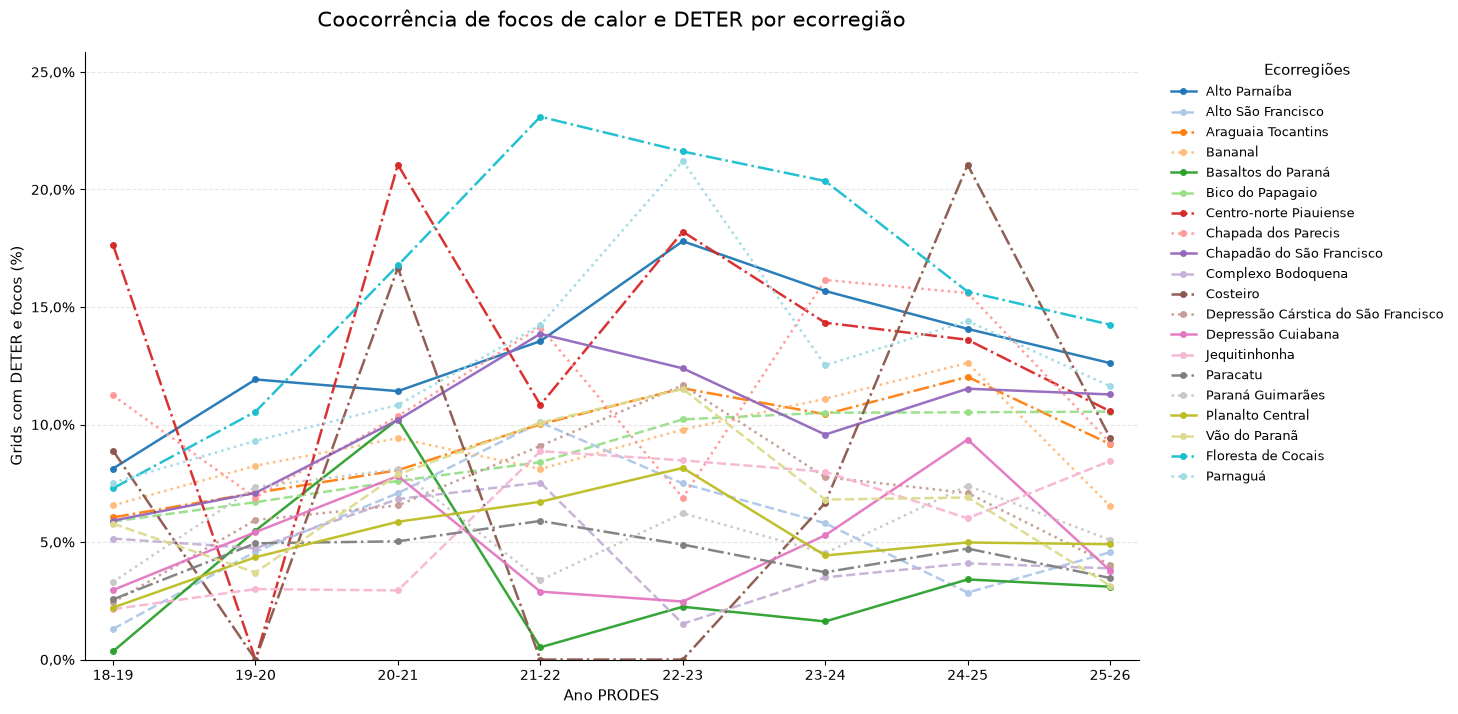


Tabela: C:\Users\gabri\OneDrive\Cerrado\SBSR\base_cartografica\analise_18_25_pos_vagner\analise_ecorregioes_anual\coocorrencia_anual_por_ecorregiao.csv
Gráfico: C:\Users\gabri\OneDrive\Cerrado\SBSR\base_cartografica\analise_18_25_pos_vagner\analise_ecorregioes_anual\coocorrencia_anual_por_ecorregiao.png
Tempo total: 00:08:32


In [2]:
# Se necessário, execute antes em outra célula:
# %pip install pandas pyogrio matplotlib

from pathlib import Path
from time import perf_counter
import gc

import pandas as pd
import pyogrio
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display


# ============================================================
# CONFIGURAÇÃO
# ============================================================

BASE = Path(
    r"C:\Users\gabri\OneDrive\Cerrado\SBSR\base_cartografica"
    r"\analise_18_25_pos_vagner"
)

ENTRADA = BASE / "outputs"
SAIDA = BASE / "analise_ecorregioes_anual"
ANOS = list(range(2018, 2026))

# Mantém o campo utilizado no seu script anexado.
CAMPO_DETER = "presenca_deter"

NOMES_ECOS = {
    1: "Alto Parnaíba",
    2: "Alto São Francisco",
    3: "Araguaia Tocantins",
    4: "Bananal",
    5: "Basaltos do Paraná",
    6: "Bico do Papagaio",
    7: "Centro-norte Piauiense",
    8: "Chapada dos Parecis",
    9: "Chapadão do São Francisco",
    10: "Complexo Bodoquena",
    11: "Costeiro",
    12: "Depressão Cárstica do São Francisco",
    13: "Depressão Cuiabana",
    14: "Jequitinhonha",
    15: "Paracatu",
    16: "Paraná Guimarães",
    17: "Planalto Central",
    18: "Vão do Paranã",
    19: "Floresta de Cocais",
    20: "Parnaguá",
}

CAMPOS = ["grid_id", "FOCO", CAMPO_DETER, "ECORREGIOES"]


# ============================================================
# FUNÇÕES
# ============================================================

def tempo_texto(segundos):
    horas, resto = divmod(int(segundos), 3600)
    minutos, segundos = divmod(resto, 60)
    return f"{horas:02d}:{minutos:02d}:{segundos:02d}"


def normalizar_ecos(valor):
    texto = "" if pd.isna(valor) else str(valor).strip()

    if texto in ("", "NENHUMA", "0"):
        return ""

    partes = texto.split("-")

    if any(not p.isdigit() or int(p) <= 0 for p in partes):
        raise ValueError(f"Código de ecorregião inválido: {valor!r}")

    codigos = sorted(set(map(int, partes)))
    desconhecidos = set(codigos) - set(NOMES_ECOS)

    if desconhecidos:
        raise ValueError(
            f"Códigos sem nome cadastrado: {sorted(desconhecidos)}"
        )

    # Remove repetições: "1-1-5" passa a ser "1-5".
    return "-".join(map(str, codigos))


def ler_ano(arquivo):
    disponiveis = set(pyogrio.read_info(arquivo)["fields"])
    faltantes = set(CAMPOS) - disponiveis

    if faltantes:
        raise ValueError(
            f"{arquivo.name}: campos ausentes: {sorted(faltantes)}"
        )

    # Somente atributos, sem carregar os polígonos.
    df = pyogrio.read_dataframe(
        arquivo,
        columns=CAMPOS,
        read_geometry=False,
    )

    if df.empty or df["grid_id"].isna().any():
        raise ValueError(f"{arquivo.name}: camada vazia ou grid_id nulo.")

    if df["grid_id"].duplicated().any():
        raise ValueError(f"{arquivo.name}: grid_id duplicado.")

    df = df.set_index("grid_id")

    for campo in ["FOCO", CAMPO_DETER]:
        valores = df[campo].astype("string").str.strip().str.upper()

        if not valores.isin(["SIM", "NAO"]).all():
            raise ValueError(
                f"{arquivo.name}: {campo} contém valores "
                "diferentes de SIM/NAO."
            )

        df[campo] = valores.eq("SIM").to_numpy(dtype=bool)

    df["ECORREGIOES"] = (
        df["ECORREGIOES"].map(normalizar_ecos).astype("category")
    )

    df["COM_DETER"] = df[CAMPO_DETER]
    df["AMBOS"] = df["FOCO"] & df["COM_DETER"]

    return df[["ECORREGIOES", "COM_DETER", "AMBOS"]]


# ============================================================
# PROCESSAMENTO ANUAL POR ECORREGIÃO
# ============================================================

inicio_total = perf_counter()

arquivos = [
    (
        ano,
        ENTRADA / (
            f"ano_prodes_{ano % 100:02d}_"
            f"{(ano + 1) % 100:02d}.geojson"
        ),
    )
    for ano in ANOS
]

faltantes = [
    str(arquivo)
    for _, arquivo in arquivos
    if not arquivo.is_file()
]

if faltantes:
    raise FileNotFoundError(
        "Arquivos não encontrados:\n" + "\n".join(faltantes)
    )

SAIDA.mkdir(parents=True, exist_ok=True)

resultados = []
referencia = None

for ano, arquivo in arquivos:
    inicio_ano = perf_counter()
    rotulo = f"{ano % 100:02d}-{(ano + 1) % 100:02d}"

    print(f"Ano PRODES {rotulo}: iniciado", flush=True)

    df = ler_ano(arquivo)

    # Confere se os grids e sua classificação espacial
    # permanecem iguais nos oito arquivos.
    if referencia is None:
        referencia = df["ECORREGIOES"].copy()

    else:
        if (
            len(df) != len(referencia)
            or not referencia.index.isin(df.index).all()
        ):
            raise ValueError(
                f"Ano {rotulo}: o conjunto de grid_id mudou."
            )

        df = df.reindex(referencia.index)

        if not df["ECORREGIOES"].astype("string").equals(
            referencia.astype("string")
        ):
            raise ValueError(
                f"Ano {rotulo}: as ecorregiões dos grids mudaram."
            )

    contagens = {
        codigo: {
            "GRIDS_TOTAIS_ECO": 0,
            "GRIDS_COM_DETER": 0,
            "GRIDS_DETER_FOCOS": 0,
        }
        for codigo in NOMES_ECOS
    }

    # Resume cada combinação antes de distribuir as contagens.
    # Não precisa expandir milhões de linhas para várias ecorregiões.
    grupos = df.groupby(
        "ECORREGIOES",
        observed=True,
    ).agg(
        GRIDS_TOTAIS_ECO=("COM_DETER", "size"),
        GRIDS_COM_DETER=("COM_DETER", "sum"),
        GRIDS_DETER_FOCOS=("AMBOS", "sum"),
    )

    for combinacao, valores in grupos.iterrows():
        if not combinacao:
            continue

        for codigo in map(int, str(combinacao).split("-")):
            for campo in contagens[codigo]:
                contagens[codigo][campo] += int(valores[campo])

    for codigo, nome in NOMES_ECOS.items():
        valores = contagens[codigo]

        numerador = valores["GRIDS_DETER_FOCOS"]
        denominador = valores["GRIDS_COM_DETER"]

        percentual = (
            100 * numerador / denominador
            if denominador > 0
            else float("nan")
        )

        resultados.append({
            "ANO_PRODES": rotulo,
            "CODIGO": codigo,
            "ECORREGIAO": nome,
            **valores,
            "PERCENTUAL": percentual,
        })

    sem_eco = int(df["ECORREGIOES"].eq("").sum())

    print(
        f"  OK | Grids sem ecorregião: {sem_eco:,} | "
        f"Tempo: {tempo_texto(perf_counter() - inicio_ano)}",
        flush=True,
    )

    del df, grupos
    gc.collect()

tabela = pd.DataFrame(resultados)


# ============================================================
# EXPORTAÇÃO DA TABELA
# ============================================================

arquivo_tabela = SAIDA / "coocorrencia_anual_por_ecorregiao.csv"

tabela.to_csv(
    arquivo_tabela,
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

rotulos_anos = [
    f"{ano % 100:02d}-{(ano + 1) % 100:02d}"
    for ano in ANOS
]

# Exibe uma tabela compacta: ecorregiões nas linhas e anos nas colunas.
percentuais = tabela.pivot(
    index="CODIGO",
    columns="ANO_PRODES",
    values="PERCENTUAL",
).reindex(
    index=list(NOMES_ECOS),
    columns=rotulos_anos,
)

visualizacao = percentuais.copy()
visualizacao.index = [
    NOMES_ECOS[codigo]
    for codigo in visualizacao.index
]
visualizacao.index.name = "ECORREGIAO"

print("\nPERCENTUAIS ANUAIS POR ECORREGIÃO")
display(visualizacao.round(2))

if tabela["PERCENTUAL"].isna().any():
    print(
        "NaN indica ausência de grids com DETER naquele "
        "ano e ecorregião. O gráfico apresenta uma lacuna."
    )


# ============================================================
# GRÁFICO — VINTE LINHAS
# ============================================================

fig, ax = plt.subplots(figsize=(17, 8))

posicoes = list(range(len(rotulos_anos)))
cores = plt.get_cmap("tab20").colors

# Além das cores, alterna traços para ajudar na identificação.
estilos = ["-", "--", "-.", ":"]

for indice, (codigo, nome) in enumerate(NOMES_ECOS.items()):
    valores = percentuais.loc[codigo].to_numpy(dtype=float)

    ax.plot(
        posicoes,
        valores,
        label=nome,
        color=cores[indice],
        linestyle=estilos[indice % len(estilos)],
        marker="o",
        markersize=4,
        linewidth=1.8,
        alpha=0.95,
    )

ax.set_title(
    "Coocorrência de focos de calor e DETER por ecorregião",
    fontsize=15,
    pad=18,
)

ax.set_xlabel("Ano PRODES", fontsize=11)

ax.set_ylabel(
    "Grids com DETER e focos (%)",
    fontsize=11,
)

ax.set_xticks(posicoes, rotulos_anos)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, _: f"{valor:.1f}%".replace(".", ",")
    )
)

maior = tabela["PERCENTUAL"].max()

if pd.isna(maior):
    maior = 0.0

ax.set_ylim(0, min(100, max(float(maior) * 1.12, 1)))
ax.set_xlim(-0.2, len(posicoes) - 0.8)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

# Legenda externa para não cobrir as linhas.
ax.legend(
    title="Ecorregiões",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=9,
    title_fontsize=11,
)

fig.subplots_adjust(
    left=0.08,
    right=0.70,
    bottom=0.14,
    top=0.90,
)

arquivo_grafico = SAIDA / "coocorrencia_anual_por_ecorregiao.png"

fig.savefig(
    arquivo_grafico,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

print(f"\nTabela: {arquivo_tabela}")
print(f"Gráfico: {arquivo_grafico}")
print(f"Tempo total: {tempo_texto(perf_counter() - inicio_total)}")